# PathogenBreak: disease-aware crop-rotation planner for Indore (Malwa, MP)

**Question:** Indore is locked into *Soybean → Wheat* every year. Which 2-year rotation keeps yields while breaking the chain of soil-borne crop diseases?

**How:** 7 real datasets → season climate → crop suitability → pathogen carry-over between crops → 2-year plan simulator → uncertainty engine (Recommend / Qualify / Withhold) → validation against real Indore data → live soil sensor advisory.

Run the cells top to bottom (**Kernel → Restart & Run All**). Keep the `data` folder next to this notebook.

In [1]:
# =====================================================================
# CELL 1: LOAD THE 7 CLEANED DATASETS
# =====================================================================
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CANDIDATES = [Path("data"),
              Path(r"C:\Users\VICTUS\OneDrive\Desktop\NASA\PathogenBreak_final\data"),
              Path.home() / "OneDrive" / "Desktop" / "NASA" / "PathogenBreak_final" / "data",
              Path.home() / "Desktop" / "PathogenBreak_final" / "data"]
DATA_DIR = next((p for p in CANDIDATES if (p / "master_season_table_indore.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Put the 'data' folder (from the zip) in the same folder as this notebook.")

def is_true(s):
    return s.astype(str).str.strip().str.lower() == "true"

season   = pd.read_csv(DATA_DIR / "master_season_table_indore.csv")
monthly  = pd.read_csv(DATA_DIR / "weather_monthly_indore.csv")
daily    = pd.read_csv(DATA_DIR / "weather_daily_indore.csv", parse_dates=["date"])
crops    = pd.read_csv(DATA_DIR / "crops_indore.csv")
evidence = pd.read_csv(DATA_DIR / "crop_pathogen_evidence.csv")
soil     = pd.read_csv(DATA_DIR / "soil_profile_indore.csv")
greenness = pd.read_csv(DATA_DIR / "ndvi_monthly_indore.csv", parse_dates=["date"])

monthly["Y"] = monthly["month"].str[:4].astype(int)
monthly["M"] = monthly["month"].str[5:7].astype(int)
daily["M"] = daily["date"].dt.month

def soil_value(name):
    return float(soil.loc[soil["property"].str.startswith(name), "value_0_30cm"].iloc[0])
soil_ph, soil_clay = soil_value("pH"), soil_value("Clay")

print("=" * 78)
print("PATHOGENBREAK - DATA SOURCES (Indore, 22.72 N 75.86 E)")
print("=" * 78)
print(f" 1. NASA POWER daily weather + soil wetness : {daily['date'].min():%b %Y} - {daily['date'].max():%b %Y} ({len(daily):,} days)")
print(f" 2. GPM IMERG rainfall (merged, preferred)  : {(daily['rain_source']=='IMERG').sum():,} days")
print(f" 3. MODIS MOD13A3 greenness (EVI)           : {greenness['evi'].notna().sum()} clear months")
print(f" 4. SoilGrids 0-30 cm                       : pH {soil_ph:.1f}, clay {soil_clay:.0f}% (Vertisol / black soil)")
print(f" 5. UPAg crop statistics, Indore            : {crops['agri_year'].nunique()} crop years, {crops['crop_name'].nunique()} crops")
print(f" 6. USDA Fungus-Host records (combined)    : {evidence['in_usda'].pipe(is_true).sum():,} crop-pathogen links")
print(f" 7. PHI-base v5.7 (gene-level)           : {evidence['in_phibase'].pipe(is_true).sum()} links confirmed by genes")
print("=" * 78)

PATHOGENBREAK - DATA SOURCES (Indore, 22.72 N 75.86 E)
 1. NASA POWER daily weather + soil wetness : Jan 2013 - Oct 2026 (5,048 days)
 2. GPM IMERG rainfall (merged, preferred)  : 2,100 days
 3. MODIS MOD13A3 greenness (EVI)           : 148 clear months
 4. SoilGrids 0-30 cm                       : pH 7.1, clay 49% (Vertisol / black soil)
 5. UPAg crop statistics, Indore            : 12 crop years, 21 crops
 6. USDA Fungus-Host records (combined)    : 7,120 crop-pathogen links
 7. PHI-base v5.7 (gene-level)           : 148 links confirmed by genes


## How PathogenBreak uses NASA Earth observation data

| NASA dataset | Variable | What it does in the model | Cells |
|---|---|---|---|
| **NASA POWER** (MERRA-2), daily 2013-2026, Indore point | `T2M` air temperature | Season temperatures → crop suitability; heat-wave stress test | 2, 4, 6 |
| | `PRECTOTCORR` rainfall | Kharif rain and Rabi stored water → suitability, waterlogging, **irrigation need**; drought / excess-rain stress tests | 2, 4, 5, 6, 7 |
| | `RH2M` humidity | Humid days (RH ≥ 80%) per season → **raises fungal disease pressure** in humid years | 2, 6 |
| | `GWETTOP` surface soil wetness | The **live sensor reading is ranked against 13 years** of NASA soil wetness for the same month → dry / normal / wet / waterlogged → field action | 11, app |
| **GPM IMERG** Final (NASA/JAXA, via Giovanni) | Daily satellite rainfall, 2020-2025 | Preferred rain source where available; cross-checked with POWER (monthly r = 0.98) | 1, 2 |
| **MODIS MOD13A3** (NASA Terra, via AppEEARS) | Monthly EVI greenness, 2013-2026 | **Validation**: confirms the crop calendar our rules use (peaks Aug & Jan, bare in May) and tracks real wheat production (r = 0.42) | 9 |

Every one of the 13 real crop years (2013-14 to 2025-26) in the uncertainty engine is built from NASA weather; that is what makes the 16-scenario test possible.

In [2]:
# =====================================================================
# CELL 2: SEASON CLIMATE FOR EVERY COMPLETE CROP YEAR
#   Kharif = Jun-Oct.  Rabi water = Sep-Oct rain (stored in black soil) + Nov-Mar rain.
# =====================================================================
K = season[season["season"] == "Kharif"].set_index("agri_year")
R = season[season["season"] == "Rabi"].set_index("agri_year")
sep_oct_rain = monthly[monthly["M"].isin([9, 10])].groupby("Y")["rain_mm"].sum()

history_climate, skipped = {}, []
for ay in K.index:
    if ay not in R.index or not (is_true(pd.Series([K.loc[ay, "complete"], R.loc[ay, "complete"]])).all()):
        skipped.append(ay)
        continue
    y = int(ay[:4])
    history_climate[y] = {
        "K_Rain": K.loc[ay, "rain_mm"], "K_Temp": K.loc[ay, "temp_mean_c"],
        "R_Rain": sep_oct_rain[y] + R.loc[ay, "rain_mm"], "R_Temp": R.loc[ay, "temp_mean_c"],
        "Humid_Days": K.loc[ay, "humid_days"],          # days with RH >= 80% -> fungal pressure
    }

clim = pd.DataFrame(history_climate).T
avg_k_rain, avg_k_temp = clim["K_Rain"].mean(), clim["K_Temp"].mean()
avg_r_rain, avg_r_temp = clim["R_Rain"].mean(), clim["R_Temp"].mean()
avg_humid = clim["Humid_Days"].mean()

print(f"Complete crop years used: {min(history_climate)}-{max(history_climate)} ({len(history_climate)} years) | skipped: {skipped}")
print(f" • Kharif normal : {avg_k_rain:.0f} mm rain, {avg_k_temp:.1f} °C, {avg_humid:.0f} humid days (RH ≥ 80%)")
print(f" • Rabi normal   : {avg_r_rain:.0f} mm water (Sep-Oct + Nov-Mar), {avg_r_temp:.1f} °C")
display(clim.round(1))

Complete crop years used: 2013-2025 (13 years) | skipped: ['2026-2027']
 • Kharif normal : 1052 mm rain, 26.7 °C, 93 humid days (RH ≥ 80%)
 • Rabi normal   : 292 mm water (Sep-Oct + Nov-Mar), 21.7 °C


,K_Rain,K_Temp,R_Rain,R_Temp,Humid_Days
2013,1323.8,25.9,257.4,20.8,120.0
2014,736.7,27.6,310.3,21.4,71.0
2015,1042.9,27.0,54.4,23.7,62.0
2016,950.9,26.5,171.6,22.0,100.0
2017,866.2,26.6,168.9,22.8,76.0
2018,711.1,26.8,88.6,21.8,74.0
2019,1435.7,26.9,500.6,20.3,104.0
2020,1123.1,26.8,309.7,22.4,97.0
2021,885.4,26.7,371.1,21.0,90.0
2022,1286.1,26.3,334.6,21.1,104.0


In [3]:
# =====================================================================
# CELL 3: PATHOGEN CARRY-OVER ENGINE (USDA + PHI-base, evidence-graded)
# =====================================================================
# Model crop name -> name used in the cleaned evidence table (UPAg names)
CROP_KEY = {"Soybean": "Soybean", "Maize": "Maize", "Cotton": "Cotton", "Groundnut": "Groundnut",
            "Pigeonpea": "Tur", "Wheat": "Wheat", "Gram": "Gram", "Mustard": "Rapeseed & Mustard",
            "Lentil": "Lentil", "Barley": "Barley"}

# Only trustworthy evidence counts (see DATA_REPORT): A = PHI-base genes AND India record,
# B = PHI-base OR repeated India records, C = >= 2 references. Single records, genus-only names
# and storage moulds / saprophytes are dropped.
GRADE_W = {"A_genomic+india": 1.0, "B_genomic_or_india": 0.8, "C_literature": 0.5}
ev = evidence[evidence["evidence_grade"].isin(GRADE_W)
              & is_true(evidence["species_level"])
              & ~is_true(evidence["likely_saprophyte_or_storage"])].copy()

# How well a pathogen survives in the field between two crops
SOILBORNE = {"Fusarium", "Rhizoctonia", "Thanatephorus", "Macrophomina", "Sclerotinia", "Sclerotium",
             "Athelia", "Pythium", "Phytophthora", "Aphanomyces", "Verticillium", "Thielaviopsis",
             "Gaeumannomyces", "Phymatotrichopsis", "Plasmodiophora", "Ralstonia", "Agrobacterium",
             "Streptomyces", "Waitea", "Ceratobasidium"}
RESIDUE = {"Cochliobolus", "Bipolaris", "Pyrenophora", "Drechslera", "Phoma", "Leptosphaeria",
           "Colletotrichum", "Alternaria", "Cercospora", "Septoria", "Zymoseptoria", "Stagonospora",
           "Parastagonospora", "Ascochyta", "Didymella", "Diaporthe", "Phomopsis", "Gibberella",
           "Exserohilum", "Setosphaeria", "Corynespora", "Myrothecium", "Curvularia", "Stemphylium",
           "Botrytis", "Botryosphaeria", "Lasiodiplodia", "Ustilago", "Tilletia", "Pseudomonas",
           "Xanthomonas", "Magnaporthe", "Pyricularia"}
def survival_w(name):
    g = str(name).split()[0]
    return 1.0 if g in SOILBORNE else (0.6 if g in RESIDUE else 0.2)   # air-borne rusts/mildews: 0.2

ev["w"] = ev["pathogen"].map(survival_w) * ev["evidence_grade"].map(GRADE_W)
crop_pathogens = {c: ev[ev["crop_name"] == k].set_index("pathogen") for c, k in CROP_KEY.items()}
phibase_set = {c: set(df.index[is_true(df["in_phibase"])]) for c, df in crop_pathogens.items()}

_memo = {}
def get_pathogen_overlap(prev_crop, next_crop):
    # Share of the NEXT crop's (weighted) disease load that the PREVIOUS crop also hosts.
    # Returns (ratio 0..1, shared_count, PHI-base-confirmed shared, examples)
    key = (prev_crop, next_crop)
    if key not in _memo:
        a, b = crop_pathogens[prev_crop], crop_pathogens[next_crop]
        shared = a.index.intersection(b.index)
        ratio = b.loc[shared, "w"].sum() / b["w"].sum() if len(b) else 0.0
        phi = sorted(phibase_set[prev_crop] & phibase_set[next_crop])
        top = b.loc[shared, "w"].sort_values(ascending=False).index[:3].tolist()
        _memo[key] = (float(ratio), len(shared), phi, top)
    return _memo[key]

print(f"Evidence kept: {len(ev):,} crop-pathogen links (grades A-C) out of {len(evidence):,}")
for c in CROP_KEY:
    print(f" • {c:<10}: {len(crop_pathogens[c]):>3} pathogens | {len(phibase_set[c]):>2} confirmed by PHI-base genes")

print("-" * 78)
for a, b in [("Soybean", "Wheat"), ("Wheat", "Barley"), ("Maize", "Wheat"), ("Soybean", "Gram"), ("Wheat", "Soybean")]:
    r, n, phi, top = get_pathogen_overlap(a, b)
    print(f"{a:>8} → {b:<8}: carry-over {r:.2f} | {n:>3} shared | PHI-base confirmed: {', '.join(phi[:3]) or '-'}")
print("-" * 78)

# Sanity tests that CAN fail
assert get_pathogen_overlap("Soybean", "Soybean")[0] == 1.0
assert get_pathogen_overlap("Wheat", "Barley")[0] > get_pathogen_overlap("Soybean", "Wheat")[0], \
    "cereal → cereal must carry more disease than legume → cereal"
print("✓ Tests passed: same crop = 100% carry-over; cereal→cereal > legume→cereal")

Evidence kept: 2,464 crop-pathogen links (grades A-C) out of 7,174
 • Soybean   : 212 pathogens | 15 confirmed by PHI-base genes
 • Maize     : 303 pathogens | 24 confirmed by PHI-base genes
 • Cotton    : 142 pathogens |  7 confirmed by PHI-base genes
 • Groundnut : 100 pathogens |  2 confirmed by PHI-base genes
 • Pigeonpea :  91 pathogens |  0 confirmed by PHI-base genes
 • Wheat     : 297 pathogens | 22 confirmed by PHI-base genes
 • Gram      :  48 pathogens |  3 confirmed by PHI-base genes
 • Mustard   :  96 pathogens | 16 confirmed by PHI-base genes
 • Lentil    :  49 pathogens |  2 confirmed by PHI-base genes
 • Barley    : 137 pathogens | 16 confirmed by PHI-base genes
------------------------------------------------------------------------------
 Soybean → Wheat   : carry-over 0.30 |  54 shared | PHI-base confirmed: Botrytis cinerea, Fusarium graminearum, Fusarium oxysporum
   Wheat → Barley  : carry-over 0.73 |  87 shared | PHI-base confirmed: Bipolaris sorokiniana, Blumeria

In [4]:
# =====================================================================
# CELL 4: CROP SUITABILITY (trapezoid curves - ASSUMPTIONS from agronomy literature)
#   (absolute_min, optimal_min, optimal_max, absolute_max)
# =====================================================================
crop_eco_profiles = {
    "Soybean":   {"rain": (400, 600, 1000, 1500), "temp": (17, 22, 30, 36), "ph": (5.0, 6.0, 7.5, 8.5)},
    "Maize":     {"rain": (350, 500, 900, 1400),  "temp": (16, 21, 30, 36), "ph": (5.0, 5.8, 7.5, 8.5)},
    "Cotton":    {"rain": (400, 600, 1100, 1600), "temp": (18, 24, 32, 38), "ph": (5.5, 6.5, 8.0, 8.8)},
    "Groundnut": {"rain": (350, 500, 800, 1200),  "temp": (19, 24, 30, 36), "ph": (5.0, 6.0, 7.2, 8.2)},
    "Pigeonpea": {"rain": (400, 600, 1000, 1500), "temp": (17, 22, 30, 37), "ph": (5.0, 6.5, 7.8, 8.5)},
    "Wheat":     {"rain": (80, 200, 450, 700),    "temp": (10, 15, 22, 27), "ph": (5.5, 6.2, 7.8, 8.5)},
    "Gram":      {"rain": (40, 100, 300, 550),    "temp": (10, 15, 25, 30), "ph": (5.5, 6.0, 7.8, 8.5)},
    "Mustard":   {"rain": (40, 100, 300, 550),    "temp": (8, 13, 22, 28),  "ph": (5.5, 6.0, 7.8, 8.5)},
    "Lentil":    {"rain": (40, 100, 300, 500),    "temp": (9, 15, 24, 29),  "ph": (5.5, 6.0, 7.8, 8.5)},
    "Barley":    {"rain": (30, 80, 300, 550),     "temp": (7, 12, 22, 28),  "ph": (5.5, 6.2, 8.3, 9.0)},
}
WATERLOG_SENSITIVE = {"Soybean", "Groundnut", "Pigeonpea", "Gram", "Lentil"}

def trapezoid(x, amin, omin, omax, amax):
    if x <= amin or x >= amax:
        return 0.0
    if omin <= x <= omax:
        return 1.0
    return (x - amin) / (omin - amin) if x < omin else (amax - x) / (amax - omax)

def score_crop_suitability(crop, rain_mm, temp_c, ph=soil_ph):
    p = crop_eco_profiles[crop]
    s = 0.4 * trapezoid(rain_mm, *p["rain"]) + 0.4 * trapezoid(temp_c, *p["temp"]) + 0.2 * trapezoid(ph, *p["ph"])
    # heavy black clay + rain above the ideal -> waterlogging loss for sensitive crops
    if crop in WATERLOG_SENSITIVE and soil_clay >= 35 and rain_mm > p["rain"][2]:
        excess = min((rain_mm - p["rain"][2]) / (p["rain"][3] - p["rain"][2]), 1.0)
        s *= 1 - 0.25 * excess
    return s

print("Suitability in a normal Indore year:")
for c in ["Soybean", "Maize", "Cotton", "Groundnut", "Pigeonpea"]:
    print(f" • {c:<10} (Kharif): {score_crop_suitability(c, avg_k_rain, avg_k_temp):.3f}")
for c in ["Wheat", "Gram", "Mustard", "Lentil", "Barley"]:
    print(f" • {c:<10} (Rabi)  : {score_crop_suitability(c, avg_r_rain, avg_r_temp):.3f}")
print("Note: in a NORMAL year all Rabi crops fit Indore well -> disease carry-over and local track record decide.")

Suitability in a normal Indore year:
 • Soybean    (Kharif): 0.934
 • Maize      (Kharif): 0.879
 • Cotton     (Kharif): 1.000
 • Groundnut  (Kharif): 0.630
 • Pigeonpea  (Kharif): 0.934
 • Wheat      (Rabi)  : 1.000
 • Gram       (Rabi)  : 1.000
 • Mustard    (Rabi)  : 1.000
 • Lentil     (Rabi)  : 1.000
 • Barley     (Rabi)  : 1.000
Note: in a NORMAL year all Rabi crops fit Indore well -> disease carry-over and local track record decide.


In [5]:
# =====================================================================
# CELL 5: CROP CALENDAR RULES + 2-YEAR ROTATION SIMULATOR
# =====================================================================
kharif_candidates = ["Soybean", "Maize", "Cotton", "Groundnut", "Pigeonpea"]
rabi_candidates   = ["Wheat", "Gram", "Mustard", "Lentil", "Barley"]
legumes  = {"Soybean", "Groundnut", "Pigeonpea", "Gram", "Lentil"}
N_HUNGRY = {"Wheat", "Maize", "Barley", "Mustard", "Cotton"}

# HARD calendar rules (a plan that breaks them is impossible, not just "worse"):
#  • Pigeonpea (Tur) is harvested Dec-Feb -> no Rabi crop can follow in the same year.
#  • Cotton is picked until Dec/Jan -> Gram, Mustard, Lentil, Barley (sown Oct-Nov) cannot follow.
#    Only LATE-sown wheat (December) is possible, with a 15% yield loss.
NO_RABI_AFTER  = {"Pigeonpea"}
AFTER_COTTON   = {"Wheat": 0.15}

def calendar_ok(seq):
    for k, r in [(seq[0], seq[1]), (seq[2], seq[3])]:
        if k in NO_RABI_AFTER or (k == "Cotton" and r not in AFTER_COTTON):
            return False
    return True

W_NEXT, W_GAP, N_BONUS, W_WATER = 0.45, 0.20, 0.025, 0.10   # assumptions - tested in the sensitivity check (Cell 6)

# WATER REALISM: Rabi crops in Malwa live on moisture stored in the black soil after the monsoon,
# topped up by irrigation from (over-used) groundwater. Irrigation need = crop water need - stored water.
# Values are ASSUMPTIONS from general agronomy (seasonal crop water use, mm).
RABI_WATER_NEED = {"Wheat": 450, "Barley": 350, "Mustard": 300, "Gram": 250, "Lentil": 220}
SOIL_STORE_MAX = 200     # mm of plant-available water a black (Vertisol) root zone can hold
def irrigation_need(crop, r_rain):
    return max(0.0, RABI_WATER_NEED.get(crop, 0) - min(r_rain, SOIL_STORE_MAX))

def evaluate_2year_plan(seq, k_rain, k_temp, r_rain, r_temp, ph=soil_ph,
                        w_next=W_NEXT, w_gap=W_GAP, n_bonus=N_BONUS, disease_mult=1.0, w_water=W_WATER):
    k1, r1, k2, r2 = seq
    late = lambda k, r: AFTER_COTTON.get(r, 0) if k == "Cotton" else 0
    s = [score_crop_suitability(k1, k_rain, k_temp, ph),
         score_crop_suitability(r1, r_rain, r_temp, ph) * (1 - late(k1, r1)),
         score_crop_suitability(k2, k_rain, k_temp, ph),
         score_crop_suitability(r2, r_rain, r_temp, ph) * (1 - late(k2, r2))]
    env = float(np.mean(s))
    nxt = [get_pathogen_overlap(seq[i], seq[i + 1])[0] for i in range(3)]   # crop -> very next crop
    gap = [get_pathogen_overlap(seq[i], seq[i + 2])[0] for i in range(2)]   # soil-borne survival over 1 year
    disease = disease_mult * (w_next * np.mean(nxt) + w_gap * np.mean(gap))
    synergy = n_bonus * sum(seq[i] in legumes and seq[i + 1] in N_HUNGRY for i in range(3))
    irr = irrigation_need(r1, r_rain) + irrigation_need(r2, r_rain)          # mm over the 2 Rabi seasons
    water = w_water * (irr / 2) / 400                                        # 400 mm/season = heavy user
    return {"Net_Score": round(env - disease + synergy - water, 4), "Env_Fit": round(env, 4),
            "Disease_Penalty": round(disease, 4), "Water_Penalty": round(water, 4), "Irrigation_mm": round(irr),
            "Synergy": synergy, "Max_Carryover": round(max(nxt + gap), 3)}

all_plans = [p for p in itertools.product(kharif_candidates, rabi_candidates, kharif_candidates, rabi_candidates)
             if calendar_ok(p)]
n_total = len(kharif_candidates) ** 2 * len(rabi_candidates) ** 2
normal = (avg_k_rain, avg_k_temp, avg_r_rain, avg_r_temp)

df_all_plans = pd.DataFrame([{"Plan_Tuple": p, "Rotation_Plan": " → ".join(p), **evaluate_2year_plan(p, *normal)}
                             for p in all_plans]).sort_values("Net_Score", ascending=False).reset_index(drop=True)

conv_tuple   = ("Soybean", "Wheat", "Soybean", "Wheat")   # what Indore does today
farmer_alt   = ("Soybean", "Gram", "Soybean", "Wheat")    # the common local alternative
CONV_2YR_SCORE = evaluate_2year_plan(conv_tuple, *normal)["Net_Score"]

print(f"Calendar rules removed {n_total - len(all_plans)} impossible plans -> {len(all_plans)} feasible plans")
print(f"   e.g. 'Cotton → Mustard' is now BLOCKED (cotton still being picked when mustard must be sown)")
print(f"Conventional Soybean → Wheat ×2 : {CONV_2YR_SCORE:.3f}  (disease penalty "
      f"{evaluate_2year_plan(conv_tuple, *normal)['Disease_Penalty']:.3f})")
print(f"Local alternative (Gram once)  : {evaluate_2year_plan(farmer_alt, *normal)['Net_Score']:.3f}")
print(f"Irrigation in a normal year (2 Rabi seasons): conventional "
      f"{evaluate_2year_plan(conv_tuple, *normal)['Irrigation_mm']} mm")
display(df_all_plans[["Rotation_Plan", "Env_Fit", "Disease_Penalty", "Water_Penalty", "Irrigation_mm", "Synergy", "Net_Score"]].head(8))

Calendar rules removed 369 impossible plans -> 256 feasible plans
   e.g. 'Cotton → Mustard' is now BLOCKED (cotton still being picked when mustard must be sown)
Conventional Soybean → Wheat ×2 : 0.609  (disease penalty 0.345)
Local alternative (Gram once)  : 0.684
Irrigation in a normal year (2 Rabi seasons): conventional 500 mm


,Rotation_Plan,Env_Fit,Disease_Penalty,Water_Penalty,Irrigation_mm,Synergy,Net_Score
0,Soybean → Mustard → Maize → Wheat,0.953,0.1703,0.0437,350,0.025,0.7640
1,Maize → Mustard → Soybean → Wheat,0.953,0.1707,0.0437,350,0.025,0.7636
2,Maize → Mustard → Soybean → Barley,0.953,0.1859,0.0312,250,0.025,0.7609
3,Soybean → Mustard → Maize → Barley,0.953,0.1886,0.0312,250,0.025,0.7582
4,Soybean → Lentil → Maize → Mustard,0.953,0.2062,0.0150,120,0.025,0.7568
5,Maize → Lentil → Soybean → Wheat,0.953,0.1879,0.0338,270,0.025,0.7564
6,Maize → Lentil → Soybean → Mustard,0.953,0.2081,0.0150,120,0.025,0.7549
7,Maize → Lentil → Soybean → Barley,0.953,0.2041,0.0213,170,0.025,0.7527


In [6]:
# =====================================================================
# CELL 6: UNCERTAINTY ENGINE - RECOMMEND / QUALIFY / WITHHOLD
#   Every plan is re-scored in each REAL past crop year + 3 stress tests and compared with
#   the conventional plan IN THE SAME YEAR. Humid years (RH data) raise disease pressure.
# =====================================================================
scenarios = {}
for y, v in history_climate.items():
    scenarios[f"{y}-{str(y+1)[2:]}"] = dict(args=(v["K_Rain"], v["K_Temp"], v["R_Rain"], v["R_Temp"]),
                                            dm=float(np.clip(v["Humid_Days"] / avg_humid, 0.7, 1.3)))
scenarios["Stress: drought -25%"]   = dict(args=(avg_k_rain*.75, avg_k_temp+.8, avg_r_rain*.75, avg_r_temp+.5), dm=0.85)
scenarios["Stress: excess rain +25%"] = dict(args=(avg_k_rain*1.25, avg_k_temp-.5, avg_r_rain*1.25, avg_r_temp), dm=1.25)
scenarios["Stress: heat +1.5 °C"]   = dict(args=(avg_k_rain, avg_k_temp+1.5, avg_r_rain, avg_r_temp+1.5), dm=1.0)
scen_names = list(scenarios)

# How much LOCAL experience Indore has with each crop (UPAg mean area, ha)
UPAG_KEY = {"Pigeonpea": "Tur", "Mustard": "Rapeseed & Mustard"}
local_area = {c: crops[crops["crop_name"] == UPAG_KEY.get(c, c)].groupby("agri_year")["area_ha"].sum().mean()
              for c in kharif_candidates + rabi_candidates}
local_area = {c: (0.0 if pd.isna(a) else a) for c, a in local_area.items()}
LOCAL_MIN_HA = 1000

pool = df_all_plans.copy()          # audit EVERY feasible plan
def scores_in(sc, **kw):
    return np.array([evaluate_2year_plan(p, *sc["args"], disease_mult=sc["dm"], **kw)["Net_Score"] for p in pool["Plan_Tuple"]])

M = np.vstack([scores_in(scenarios[s]) for s in scen_names]).T          # plans × scenarios
conv = np.array([evaluate_2year_plan(conv_tuple, *scenarios[s]["args"], disease_mult=scenarios[s]["dm"])["Net_Score"] for s in scen_names])
best = M.max(axis=0)
# "Best SAFE plan" per scenario = best plan using only crops Indore already grows at scale
local_ok = np.array([all(local_area[c] >= LOCAL_MIN_HA for c in t) for t in pool["Plan_Tuple"]])
best_local = M[local_ok].max(axis=0) if local_ok.any() else best

rows = []
for i, (_, r) in enumerate(pool.iterrows()):
    margins = M[i] - conv
    win = float((margins > 0).mean())
    regret = float((best_local - M[i]).mean()) if local_ok[i] else float((best - M[i]).mean())
    new_crops = [c for c in set(r["Plan_Tuple"]) if local_area[c] < LOCAL_MIN_HA]
    lost = [scen_names[j] for j in np.where(margins <= 0)[0]]
    if win < 0.5 or margins.mean() <= 0:
        dec, why = "Withhold", f"beats conventional in only {win:.0%} of years"
    elif win >= 0.8 and margins.mean() >= 0.03 and regret <= 0.03 and not new_crops:
        dec, why = "Recommend", f"beats conventional in {win:.0%} of {len(margins)} scenarios (avg {margins.mean():+.3f}, worst {margins.min():+.3f})"
    else:
        dec = "Qualify"
        cav = []
        if new_crops: cav.append(f"little local experience with {', '.join(sorted(new_crops))} (<{LOCAL_MIN_HA:,} ha in Indore) - pilot plot first")
        if regret > 0.03: cav.append(f"{regret:.3f} pts below the best plan")
        if lost: cav.append(f"weaker in {', '.join(lost[:2])}")
        if "Cotton" in r["Plan_Tuple"]: cav.append("wheat sown late after cotton")
        why = "; ".join(cav) or "small margin"
    rows.append({"Rotation_Plan": r["Rotation_Plan"], "Plan_Tuple": r["Plan_Tuple"], "Net_Score": r["Net_Score"],
                 "Mean_Score": round(M[i].mean(), 4), "Env_Fit": r["Env_Fit"], "Disease_Penalty": r["Disease_Penalty"],
                 "Irrigation_mm": r["Irrigation_mm"],
                 "Win_Pct": round(win * 100), "Mean_Margin": round(margins.mean(), 3), "Worst_Margin": round(margins.min(), 3),
                 "Decision": dec, "Explanation": why})

order = {"Recommend": 0, "Qualify": 1, "Withhold": 2}
df_audited = (pd.DataFrame(rows).assign(_o=lambda d: d["Decision"].map(order))
              .sort_values(["_o", "Mean_Score"], ascending=[True, False]).drop(columns="_o").reset_index(drop=True))
top = df_audited.iloc[0]                                    # best RECOMMENDED plan (safe to adopt now)
pilot = df_audited.sort_values("Mean_Score", ascending=False).iloc[0]   # highest potential overall

# Sensitivity: change every weight by about ±33-50% (81 combinations)
ranks, beats = [], []
for wn, wg, nb, ww in itertools.product([0.30, 0.45, 0.60], [0.13, 0.20, 0.27], [0.017, 0.025, 0.033], [0.05, 0.10, 0.15]):
    tot = sum(scores_in(scenarios[s], w_next=wn, w_gap=wg, n_bonus=nb, w_water=ww) for s in scen_names)
    ctot = sum(evaluate_2year_plan(conv_tuple, *scenarios[s]["args"], disease_mult=scenarios[s]["dm"],
                                   w_next=wn, w_gap=wg, n_bonus=nb, w_water=ww)["Net_Score"] for s in scen_names)
    idx = list(pool["Rotation_Plan"]).index(top["Rotation_Plan"])
    ranks.append(int((tot[local_ok] > tot[idx]).sum()) + 1)      # rank among SAFE (local-crop) plans
    beats.append(tot[idx] > ctot)

# Honesty check: how much of the advantage comes from the disease assumption?
env_top  = np.mean([evaluate_2year_plan(top["Plan_Tuple"], *scenarios[s]["args"])["Env_Fit"] for s in scen_names])
env_conv = np.mean([evaluate_2year_plan(conv_tuple, *scenarios[s]["args"])["Env_Fit"] for s in scen_names])

print(f"Scenarios: {len(history_climate)} real crop years + 3 stress tests = {len(scen_names)}")
print(df_audited["Decision"].value_counts().to_string())
print("-" * 78)
print(f"RECOMMENDED  : {top['Rotation_Plan']}  [{top['Decision'].upper()}]")
print(f"Why          : {top['Explanation']}")
if pilot["Rotation_Plan"] != top["Rotation_Plan"]:
    print(f"PILOT OPTION : {pilot['Rotation_Plan']}  (highest score {pilot['Mean_Score']:.3f}, but {pilot['Explanation']})")
print(f"Sensitivity  : stays the #1 safe plan in {sum(r == 1 for r in ranks)}/{len(ranks)} weight settings, "
      f"beats conventional in {sum(beats)}/{len(beats)}")
print(f"Env-only fit : top {env_top:.3f} vs conventional {env_conv:.3f}  -> the gain comes mainly from breaking disease carry-over")
print("               (that is the model's central assumption - it is checked against real data in Cell 9, not proven)")
display(df_audited[["Rotation_Plan", "Mean_Score", "Win_Pct", "Mean_Margin", "Worst_Margin", "Decision", "Explanation"]].head(8))

Scenarios: 13 real crop years + 3 stress tests = 16
Decision
Qualify      207
Withhold      47
Recommend      2
------------------------------------------------------------------------------
RECOMMENDED  : Maize → Gram → Soybean → Wheat  [RECOMMEND]
Why          : beats conventional in 100% of 16 scenarios (avg +0.145, worst +0.045)
PILOT OPTION : Soybean → Mustard → Maize → Wheat  (highest score 0.681, but little local experience with Mustard (<1,000 ha in Indore) - pilot plot first)
Sensitivity  : stays the #1 safe plan in 81/81 weight settings, beats conventional in 81/81
Env-only fit : top 0.873 vs conventional 0.883  -> the gain comes mainly from breaking disease carry-over
               (that is the model's central assumption - it is checked against real data in Cell 9, not proven)


,Rotation_Plan,Mean_Score,Win_Pct,Mean_Margin,Worst_Margin,Decision,Explanation
0,Maize → Gram → Soybean → Wheat,0.6629,100,0.145,0.045,Recommend,beats conventional in 100% of 16 scenarios (av...
1,Soybean → Gram → Maize → Wheat,0.6526,100,0.135,0.035,Recommend,beats conventional in 100% of 16 scenarios (av...
2,Soybean → Mustard → Maize → Wheat,0.6812,100,0.164,0.093,Qualify,"little local experience with Mustard (<1,000 h..."
3,Maize → Mustard → Soybean → Wheat,0.6808,100,0.163,0.093,Qualify,"little local experience with Mustard (<1,000 h..."
4,Groundnut → Barley → Soybean → Mustard,0.6781,100,0.161,0.009,Qualify,"little local experience with Barley, Groundnut..."
5,Maize → Mustard → Soybean → Barley,0.6756,100,0.158,0.031,Qualify,"little local experience with Barley, Mustard (..."
6,Groundnut → Mustard → Soybean → Wheat,0.6741,100,0.157,0.062,Qualify,"little local experience with Groundnut, Mustar..."
7,Soybean → Mustard → Maize → Barley,0.6728,100,0.155,0.028,Qualify,"little local experience with Barley, Mustard (..."


In [7]:
# =====================================================================
# CELL 7: FARMER CHECK - INCOME AND WATER -> THREE OPTIONS FOR THE FARMER
#   Net return = (MSP - cost of production) × yield.  Prices: Govt of India MSP, Kharif 2026-27 and
#   Rabi 2026-27; costs: CACP A2+FL cost of production (Rabi: published; Kharif: from published margins).
#   Yields: Indore's own 12-year average (UPAg) where Indore grows > 1,000 ha, else the Madhya Pradesh average.
# =====================================================================
MSP  = {"Soybean": 5708, "Maize": 2410, "Cotton": 8267, "Groundnut": 7517, "Pigeonpea": 8450,
        "Wheat": 2585, "Gram": 5875, "Mustard": 6200, "Lentil": 7000, "Barley": 2150}        # Rs/quintal
COST = {"Soybean": 5708/1.50, "Maize": 2410/1.56, "Cotton": 8267/1.50, "Groundnut": 7517/1.50, "Pigeonpea": 8450/1.54,
        "Wheat": 1239, "Gram": 3699, "Mustard": 6200/1.93, "Lentil": 3705, "Barley": 1361}  # Rs/quintal
# Indicative Indore-area MANDI prices (Rs/quintal) - one snapshot, NOT a forecast; prices swing by variety and date:
#   soybean 4,130 (MP Bhavantar model rate, 13 Nov 2025, harvest season) | wheat 2,351, gram (desi) 5,300,
#   maize 1,951 (Mhow APMC averages, May 2026) | mustard 6,010 (Indore APMC modal, Apr 2026).
# Crops without a local quote keep their MSP.
MANDI = {**MSP, "Soybean": 4130, "Maize": 1951, "Wheat": 2351, "Gram": 5300, "Mustard": 6010}
LINT_TO_KAPAS = 1 / 0.34          # UPAg reports cotton lint; MSP is paid on kapas (seed cotton)
INCOME_SAFE = -0.05               # "keeps income": at most 5% below today's practice
mp_crops = pd.read_csv(DATA_DIR / "crops_madhya_pradesh.csv")

def crop_yield(crop):
    name, season_ = UPAG_KEY.get(crop, crop), ("Kharif" if crop in kharif_candidates else "Rabi")
    if local_area[crop] >= LOCAL_MIN_HA:
        d, src = crops[(crops["crop_name"] == name) & (crops["season"] == season_)], "Indore"
    else:
        d, src = mp_crops[(mp_crops["crop_name"] == name) & (mp_crops["season"] == season_)], "MP"
    y = d["production_t"].sum() / d["area_ha"].sum() * 1000
    return (y * LINT_TO_KAPAS if crop == "Cotton" else y), src

YIELD = {c: crop_yield(c) for c in MSP}
def net_per_ha(crop, late=0.0, price=MSP):
    y = YIELD[crop][0] * (1 - late)
    return (price[crop] - COST[crop]) * y / 100

def plan_income(seq, price=MSP):
    lates = [0, AFTER_COTTON.get(seq[1], 0) if seq[0] == "Cotton" else 0,
             0, AFTER_COTTON.get(seq[3], 0) if seq[2] == "Cotton" else 0]
    return sum(net_per_ha(c, l, price) for c, l in zip(seq, lates))

conv_income = plan_income(conv_tuple)
conv_income_mandi = plan_income(conv_tuple, MANDI)
df_audited["Income_Rs_2yr"] = [round(plan_income(t), -2) for t in df_audited["Plan_Tuple"]]
df_audited["Income_vs_Today"] = df_audited["Income_Rs_2yr"] / conv_income - 1
df_audited["Local_Crops"] = [all(local_area[c] >= LOCAL_MIN_HA for c in t) for t in df_audited["Plan_Tuple"]]
robust = df_audited[(df_audited["Win_Pct"] >= 80) & (df_audited["Mean_Margin"] > 0)]

OPTIONS = {
    "Keep income":     robust[robust["Local_Crops"] & (robust["Income_vs_Today"] >= INCOME_SAFE)]
                         .sort_values("Mean_Score", ascending=False).iloc[0],
    "Strongest break": df_audited.iloc[0],                       # best RECOMMEND plan from Cell 6
    "Pilot plot":      robust[~robust["Local_Crops"] & (robust["Income_vs_Today"] >= 0)]
                         .sort_values("Mean_Score", ascending=False).iloc[0],
}
conv_eval = evaluate_2year_plan(conv_tuple, *normal)
rows = [{"Option": "Today", "Rotation": " → ".join(conv_tuple), "Score": round(conv.mean(), 3),
         "Disease_vs_Today": "0%", "Irrigation_mm": conv_eval["Irrigation_mm"], "Income_Rs_2yr": round(conv_income, -2),
         "Income_vs_Today": "0%", "Mandi_Income_Rs_2yr": round(conv_income_mandi, -2), "Mandi_vs_Today": "0%"}]
for name, r in OPTIONS.items():
    e = evaluate_2year_plan(r["Plan_Tuple"], *normal)
    rows.append({"Option": name, "Rotation": r["Rotation_Plan"], "Score": r["Mean_Score"],
                 "Disease_vs_Today": f"{e['Disease_Penalty']/conv_eval['Disease_Penalty']-1:+.0%}",
                 "Irrigation_mm": e["Irrigation_mm"], "Income_Rs_2yr": r["Income_Rs_2yr"],
                 "Income_vs_Today": f"{r['Income_vs_Today']:+.0%}",
                 "Mandi_Income_Rs_2yr": round(plan_income(r["Plan_Tuple"], MANDI), -2),
                 "Mandi_vs_Today": f"{plan_income(r['Plan_Tuple'], MANDI) / conv_income_mandi - 1:+.0%}"})
farm = pd.DataFrame(rows)

print("Yield used (kg/ha): " + " | ".join(f"{c} {YIELD[c][0]:,.0f} ({YIELD[c][1]})" for c in MSP))
print("=" * 90)
print("THREE OPTIONS FOR AN INDORE FARMER (normal year; income = net return over cost, Rs/ha over 2 years,")
print("at MSP and at indicative Indore mandi prices)")
display(farm)

sb = OPTIONS["Strongest break"]
gap = conv_income - sb["Income_Rs_2yr"]
if gap > 0:
    gram_q = YIELD["Gram"][0] / 100 * sb["Plan_Tuple"].count("Gram")
    cereal_net = sum(net_per_ha(c) for c in sb["Plan_Tuple"] if c in ("Soybean", "Wheat"))
    print(f"'Strongest break' costs {gap:,.0f} Rs/ha over 2 years at MSP. It would break even if:")
    print(f"   • gram sold at ≥ Rs {MSP['Gram'] + gap / gram_q:,.0f}/quintal (MSP Rs {MSP['Gram']:,}), or")
    print(f"   • the soybean and wheat in the rotation yield {gap / cereal_net:.0%} more because of less disease (to be field-tested).")
ws = conv_eval["Irrigation_mm"] - evaluate_2year_plan(sb["Plan_Tuple"], *normal)["Irrigation_mm"]
print(f"   It also saves {ws:.0f} mm of groundwater per hectare (= {ws*10:,.0f} m³/ha, ~{ws/60:.0f} fewer irrigations).")
sb_m = plan_income(sb["Plan_Tuple"], MANDI) / conv_income_mandi - 1
print(f"At the mandi-price snapshot the gap is {sb_m:+.0%} (vs {sb['Income_vs_Today']:+.0%} at MSP) - "
      + ("the trade-off holds either way." if sb_m < -0.05 else "much smaller at market prices."))
print("Notes: MSP is a price floor (mandi prices differ). Costs are all-India averages. Income is NOT part of the")
print("       disease score - it is shown separately so the farmer can choose the trade-off.")

Yield used (kg/ha): Soybean 1,170 (Indore) | Maize 2,235 (Indore) | Cotton 1,151 (MP) | Groundnut 1,823 (MP) | Pigeonpea 1,065 (MP) | Wheat 4,543 (Indore) | Gram 1,325 (Indore) | Mustard 1,368 (MP) | Lentil 1,013 (MP) | Barley 1,871 (MP)
THREE OPTIONS FOR AN INDORE FARMER (normal year; income = net return over cost, Rs/ha over 2 years,
at MSP and at indicative Indore mandi prices)


,Option,Rotation,Score,Disease_vs_Today,Irrigation_mm,Income_Rs_2yr,Income_vs_Today,Mandi_Income_Rs_2yr,Mandi_vs_Today
0,Today,Soybean → Wheat → Soybean → Wheat,0.5170,0%,500,166800.0,0%,108600.0,0%
1,Keep income,Maize → Wheat → Soybean → Wheat,0.5509,-17%,500,163900.0,-2%,113900.0,+5%
2,Strongest break,Maize → Gram → Soybean → Wheat,0.6629,-45%,300,131600.0,-21%,84600.0,-22%
3,Pilot plot,Groundnut → Mustard → Soybean → Wheat,0.6741,-54%,350,170000.0,+2%,138300.0,+27%


'Strongest break' costs 35,207 Rs/ha over 2 years at MSP. It would break even if:
   • gram sold at ≥ Rs 8,533/quintal (MSP Rs 5,875), or
   • the soybean and wheat in the rotation yield 42% more because of less disease (to be field-tested).
   It also saves 200 mm of groundwater per hectare (= 2,000 m³/ha, ~3 fewer irrigations).
At the mandi-price snapshot the gap is -22% (vs -21% at MSP) - the trade-off holds either way.
Notes: MSP is a price floor (mandi prices differ). Costs are all-India averages. Income is NOT part of the
       disease score - it is shown separately so the farmer can choose the trade-off.


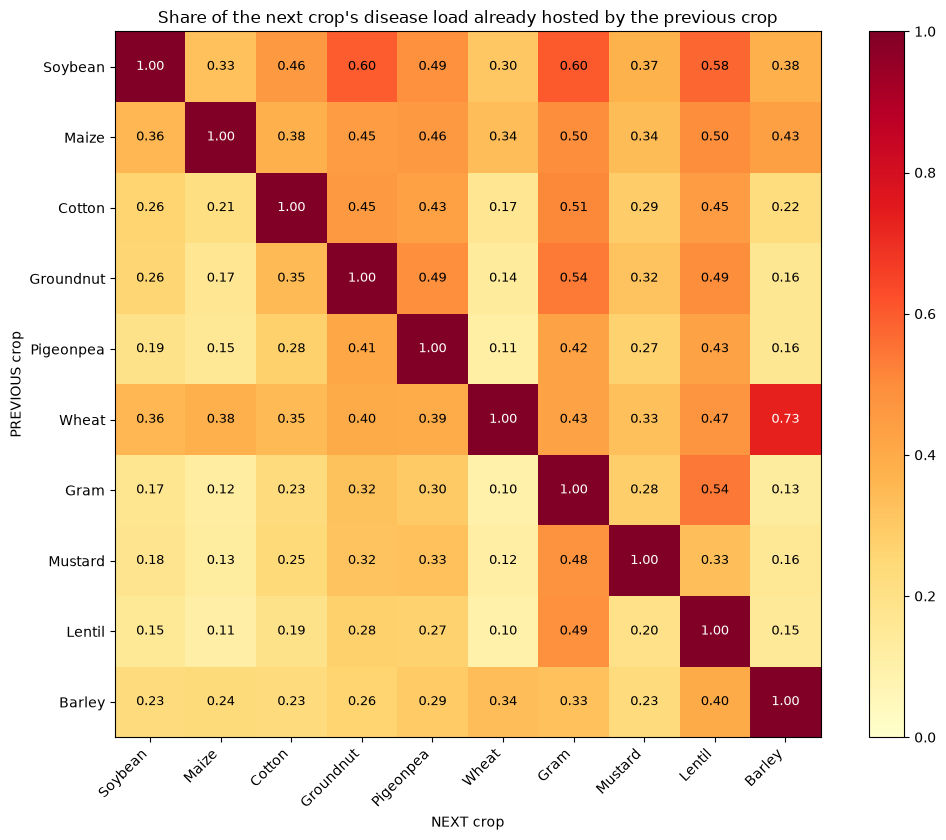

Soil-borne pathogens shared by the most of our 10 crops:


,Crops,N_Crops,PHI_base,India
pathogen,,,,
Fusarium equiseti,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean, Wheat",10,,yes
Rhizoctonia solani,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean, Wheat",10,,yes
Sclerotium rolfsii,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean, Wheat",10,,yes
Fusarium oxysporum,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean, Wheat",10,yes,yes
Fusarium solani,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Pigeonpea, Soybean, Wheat",9,,yes
Fusarium incarnatum,"Barley, Cotton, Gram, Groundnut, Maize, Mustard, Pigeonpea, Soybean, Wheat",9,,yes
Fusarium verticillioides,"Barley, Cotton, Gram, Groundnut, Lentil, Maize, Pigeonpea, Soybean, Wheat",9,yes,yes
Sclerotinia sclerotiorum,"Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean, Wheat",8,yes,yes
Macrophomina phaseolina,"Cotton, Gram, Groundnut, Lentil, Maize, Mustard, Pigeonpea, Soybean",8,,yes


Reading the map: Soybean→Soybean and Wheat→Wheat = 1.00 (everything returns); Gram→Soybean = 0.17, Soybean→Wheat = 0.30.


In [8]:
# =====================================================================
# CELL 8: PATHOGEN CARRY-OVER MAP - which crop passes disease to which?
# =====================================================================
all_crops = kharif_candidates + rabi_candidates
heat = pd.DataFrame([[get_pathogen_overlap(a, b)[0] for b in all_crops] for a in all_crops],
                    index=all_crops, columns=all_crops)
fig, ax = plt.subplots(figsize=(10.5, 8.5))
im = ax.imshow(heat.values, cmap="YlOrRd", vmin=0, vmax=1)
ax.set_xticks(range(10), all_crops, rotation=45, ha="right"); ax.set_yticks(range(10), all_crops)
ax.set_xlabel("NEXT crop"); ax.set_ylabel("PREVIOUS crop")
for i in range(10):
    for j in range(10):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else "black")
ax.set_title("Share of the next crop's disease load already hosted by the previous crop")
plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.savefig("pathogen_heatmap.png", dpi=150); plt.show()

# Which soil-borne pathogens connect the most crops? (the ones rotation must break)
links = ev[ev["crop_name"].isin(CROP_KEY.values())].copy()
links["genus"] = links["pathogen"].str.split().str[0]
soil_links = links[links["genus"].isin(SOILBORNE)]
key_back = {v: k for k, v in CROP_KEY.items()}
top_soil = (soil_links.groupby("pathogen")
            .agg(Crops=("crop_name", lambda x: ", ".join(sorted(key_back[c] for c in set(x)))),
                 N_Crops=("crop_name", "nunique"),
                 PHI_base=("in_phibase", lambda x: "yes" if is_true(x).any() else ""),
                 India=("recorded_in_india", lambda x: "yes" if is_true(x).any() else ""))
            .sort_values("N_Crops", ascending=False).head(10))
print("Soil-borne pathogens shared by the most of our 10 crops:")
with pd.option_context("display.max_colwidth", None):
    display(top_soil)
print("Reading the map: Soybean→Soybean and Wheat→Wheat = 1.00 (everything returns); "
      f"Gram→Soybean = {heat.loc['Gram','Soybean']:.2f}, Soybean→Wheat = {heat.loc['Soybean','Wheat']:.2f}.")

CHECK 1 - our climate inputs match real harvests (n = 12 years, so treat as indicative):
   Rabi water (model input) vs Indore wheat production : r = +0.51
   Satellite Rabi greenness (EVI) vs wheat production   : r = +0.42
CHECK 2 - satellite confirms the crop calendar the rules use:
   EVI peaks in month 8 (Kharif soybean) and month 1 (Rabi); lowest in month 5 (fields empty)
CHECK 3 - the problem is real (UPAg): Indore is narrowing to soybean-wheat
   Gram area   :    78,801 ha (2013-19) ->     8,883 ha (2019-25)  (-89%)
   Wheat area  :   121,445 ha (2013-19) ->   190,055 ha (2019-25)  (+56%)
   Soybean     : ~233,874 ha every year, yield flat at ~1,166 kg/ha
CHECK 4 - real yields across Madhya Pradesh (UPAg, district + year fixed effects, 95% bootstrap CI):
   Soybean: +10 points of last year's soybean share -> -2.0% yield this year (95% CI -4.5% to +1.3%; 48 districts) - NOT statistically significant
   Wheat  : +10 points of last year's wheat share -> -1.1% yield this year (95% C

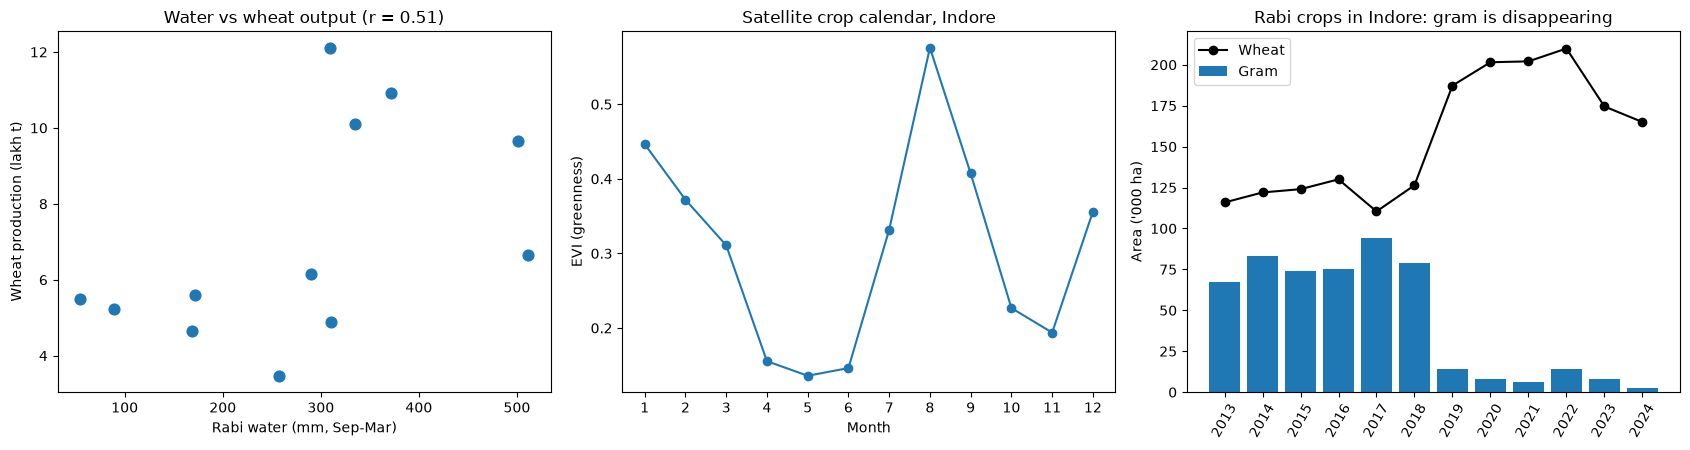

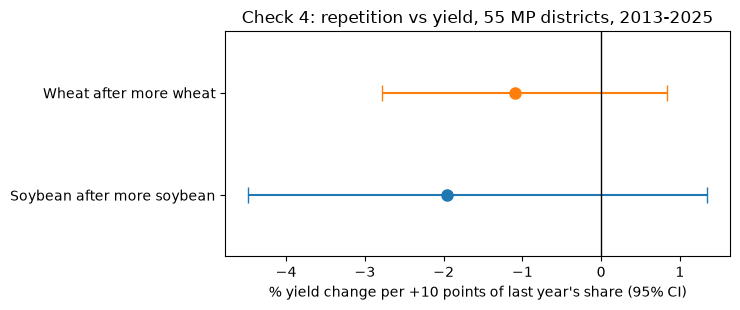

In [9]:
# =====================================================================
# CELL 9: VALIDATION AGAINST REAL INDORE DATA (UPAg yields + MODIS greenness)
# =====================================================================
def crop_series(name, s, col):
    return crops[(crops["crop_name"] == name) & (crops["season"] == s)].set_index("agri_year")[col]

v = pd.DataFrame({"Rabi_Water": {f"{y}-{y+1}": d["R_Rain"] for y, d in history_climate.items()},
                  "Rabi_EVI_Peak": R["evi_peak"],
                  "Wheat_Prod_t": crop_series("Wheat", "Rabi", "production_t"),
                  "Wheat_Area": crop_series("Wheat", "Rabi", "area_ha"),
                  "Gram_Area": crop_series("Gram", "Rabi", "area_ha"),
                  "Soy_Area": crop_series("Soybean", "Kharif", "area_ha"),
                  "Soy_Yield": crop_series("Soybean", "Kharif", "yield_kg_ha")}).dropna(subset=["Wheat_Prod_t"])
r_water = v["Rabi_Water"].corr(v["Wheat_Prod_t"])
r_evi   = v["Rabi_EVI_Peak"].corr(v["Wheat_Prod_t"])
evi_clim = greenness.dropna(subset=["evi"]).groupby(greenness["date"].dt.month)["evi"].mean()
early, late = v.loc[:"2018-2019"], v.loc["2019-2020":]

print("CHECK 1 - our climate inputs match real harvests (n = 12 years, so treat as indicative):")
print(f"   Rabi water (model input) vs Indore wheat production : r = {r_water:+.2f}")
print(f"   Satellite Rabi greenness (EVI) vs wheat production   : r = {r_evi:+.2f}")
print("CHECK 2 - satellite confirms the crop calendar the rules use:")
print(f"   EVI peaks in month {evi_clim.idxmax()} (Kharif soybean) and month {evi_clim.loc[[11,12,1,2,3]].idxmax()} (Rabi); "
      f"lowest in month {evi_clim.idxmin()} (fields empty)")
print("CHECK 3 - the problem is real (UPAg): Indore is narrowing to soybean-wheat")
print(f"   Gram area   : {early['Gram_Area'].mean():>9,.0f} ha (2013-19) -> {late['Gram_Area'].mean():>9,.0f} ha (2019-25)  "
      f"({late['Gram_Area'].mean()/early['Gram_Area'].mean()-1:+.0%})")
print(f"   Wheat area  : {early['Wheat_Area'].mean():>9,.0f} ha (2013-19) -> {late['Wheat_Area'].mean():>9,.0f} ha (2019-25)  "
      f"({late['Wheat_Area'].mean()/early['Wheat_Area'].mean()-1:+.0%})")
print(f"   Soybean     : ~{v['Soy_Area'].mean():,.0f} ha every year, yield flat at ~{v['Soy_Yield'].mean():,.0f} kg/ha")

# CHECK 4 - does breaking the chain show up in real yields? 55 MP districts × 12 years (UPAg).
#   Within each district (district + year fixed effects): when last year's soybean (wheat) share was higher
#   than usual, is this year's soybean (wheat) yield lower?  95% CI from a district bootstrap.
mpc = pd.read_csv(DATA_DIR / "crops_madhya_pradesh.csv")
def _piv(season_, crop, col="area_ha"):
    return mpc[(mpc["season"] == season_) & (mpc["crop_name"] == crop)].set_index(["district_name", "agri_year"])[col]
pnl = pd.DataFrame({"soy": _piv("Kharif", "Soybean"), "soy_y": _piv("Kharif", "Soybean", "yield_kg_ha"),
                    "wht": _piv("Rabi", "Wheat"), "wht_y": _piv("Rabi", "Wheat", "yield_kg_ha"),
                    "kh": mpc[mpc["season"] == "Kharif"].groupby(["district_name", "agri_year"])["area_ha"].sum(),
                    "rb": mpc[mpc["season"] == "Rabi"].groupby(["district_name", "agri_year"])["area_ha"].sum()}).reset_index()
pnl["yr"] = pnl["agri_year"].str[:4].astype(int)
pnl = pnl.sort_values(["district_name", "yr"])
pnl["soy_share_lag"] = (pnl["soy"] / pnl["kh"]).groupby(pnl["district_name"]).shift(1)
pnl["wht_share_lag"] = (pnl["wht"] / pnl["rb"]).groupby(pnl["district_name"]).shift(1)

def fe_slope(df, y, x):
    d = df[[y, x, "district_name", "agri_year"]].dropna().reset_index(drop=True)
    d[y] = np.log(d[y])
    for c in (y, x):                                    # two-way demeaning (district + year effects)
        for _ in range(20):
            d[c] = d[c] - d.groupby("district_name")[c].transform("mean")
            d[c] = d[c] - d.groupby("agri_year")[c].transform("mean")
    return float((d[x] * d[y]).sum() / (d[x] ** 2).sum())

def fe_test(df, y, x, n_boot=300, seed=1):
    rng = np.random.default_rng(seed)
    ids = df["district_name"].unique()
    grp = {i: df[df["district_name"] == i] for i in ids}
    boots = []
    for _ in range(n_boot):
        pick = rng.choice(ids, len(ids))
        b = pd.concat([grp[i].assign(district_name=f"{i}#{k}") for k, i in enumerate(pick)], ignore_index=True)
        boots.append(fe_slope(b, y, x))
    est = fe_slope(df, y, x)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return est, lo, hi, df["district_name"].nunique()

soy_t = fe_test(pnl[pnl["soy"] >= 10000], "soy_y", "soy_share_lag")
wht_t = fe_test(pnl[pnl["wht"] >= 10000], "wht_y", "wht_share_lag")
print("CHECK 4 - real yields across Madhya Pradesh (UPAg, district + year fixed effects, 95% bootstrap CI):")
for name, (est, lo, hi, n) in [("Soybean", soy_t), ("Wheat", wht_t)]:
    sig = "significant" if (hi < 0 or lo > 0) else "NOT statistically significant"
    print(f"   {name:<7}: +10 points of last year's {name.lower()} share -> {est*0.10:+.1%} yield this year "
          f"(95% CI {lo*0.10:+.1%} to {hi*0.10:+.1%}; {n} districts) - {sig}")
print("   Direction matches PathogenBreak (more repetition -> lower yield), but district averages over 12 years")
print("   are too coarse to prove it. A field trial is the real test - this is said openly.")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].scatter(v["Rabi_Water"], v["Wheat_Prod_t"] / 1e5, s=60)
ax[0].set(xlabel="Rabi water (mm, Sep-Mar)", ylabel="Wheat production (lakh t)", title=f"Water vs wheat output (r = {r_water:.2f})")
ax[1].plot(evi_clim.index, evi_clim.values, marker="o")
ax[1].set(xticks=range(1, 13), xlabel="Month", ylabel="EVI (greenness)", title="Satellite crop calendar, Indore")
idx = [a[:4] for a in v.index]
ax[2].bar(idx, v["Gram_Area"] / 1e3, label="Gram")
ax[2].plot(idx, v["Wheat_Area"] / 1e3, color="k", marker="o", label="Wheat")
ax[2].set(ylabel="Area ('000 ha)", title="Rabi crops in Indore: gram is disappearing"); ax[2].legend()
ax[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("validation.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, (name, (est, lo, hi, n)) in enumerate([("Soybean after more soybean", soy_t), ("Wheat after more wheat", wht_t)]):
    ax.errorbar(est * 10, i, xerr=[[est * 10 - lo * 10], [hi * 10 - est * 10]], fmt="o", capsize=6, ms=8)
ax.axvline(0, color="k", lw=1)
ax.set_yticks([0, 1], ["Soybean after more soybean", "Wheat after more wheat"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("% yield change per +10 points of last year's share (95% CI)")
ax.set_title("Check 4: repetition vs yield, 55 MP districts, 2013-2025")
plt.tight_layout(); plt.savefig("rotation_evidence.png", dpi=150); plt.show()

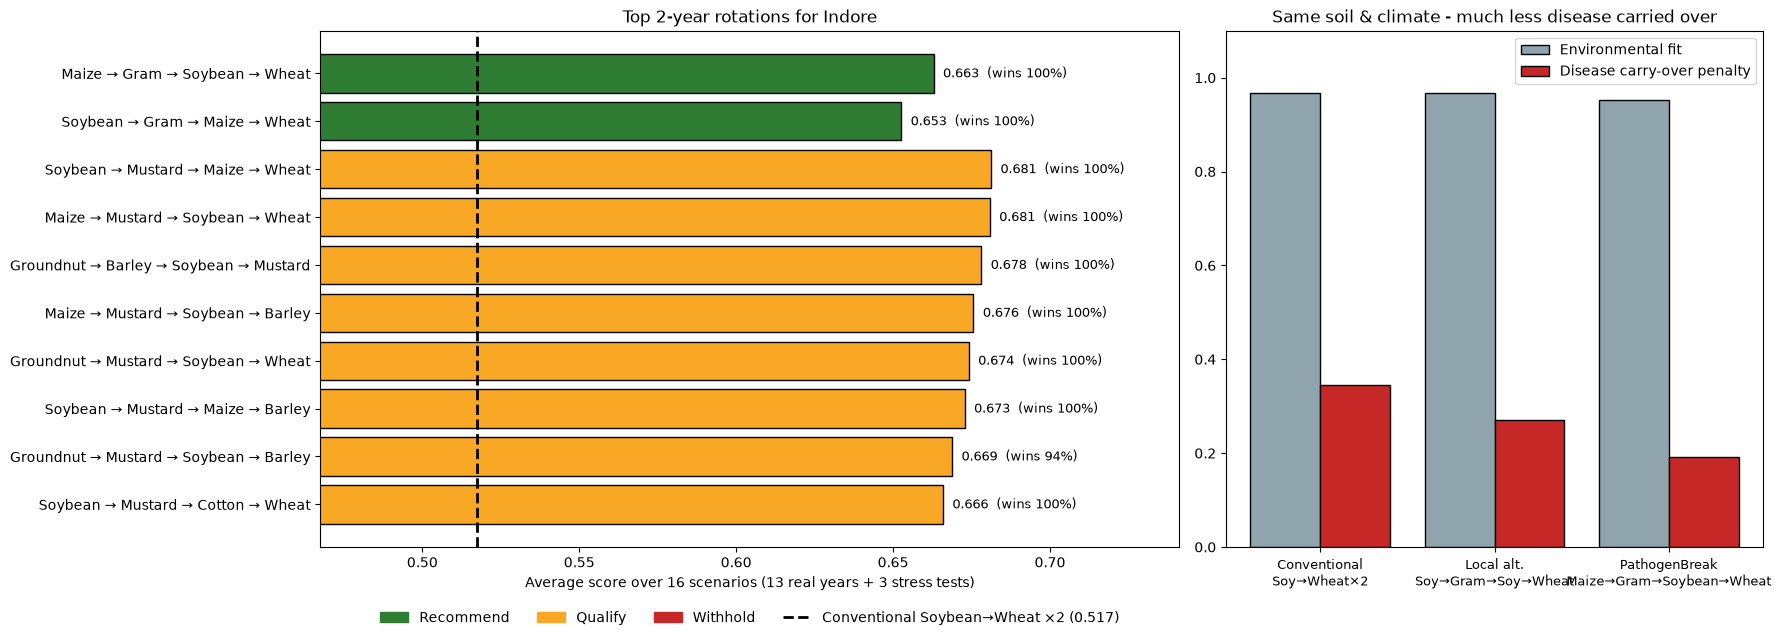

PATHOGENBREAK - FINAL RESULT (Indore, MP)
Conventional      : Soybean → Wheat → Soybean → Wheat   avg 0.517
PathogenBreak top : Maize → Gram → Soybean → Wheat   avg 0.663 (+0.145)
Decision          : RECOMMEND - beats conventional in 100% of 16 scenarios (avg +0.145, worst +0.045)
------------------------------------------------------------------------------
Farmer options (Cell 7):
  Keep income     : Maize → Wheat → Soybean → Wheat          score 0.551 | income -2%
  Strongest break : Maize → Gram → Soybean → Wheat           score 0.663 | income -21%
  Pilot plot      : Groundnut → Mustard → Soybean → Wheat    score 0.674 | income +2%
Saved: dashboard.png, validation.png, pathogenbreak_results.csv


In [10]:
# =====================================================================
# CELL 10: DECISION DASHBOARD + EXPORT
# =====================================================================
colors = {"Recommend": "#2e7d32", "Qualify": "#f9a825", "Withhold": "#c62828"}
show = df_audited.head(10).iloc[::-1]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.6, 1]})
a1.barh(show["Rotation_Plan"], show["Mean_Score"], color=[colors[d] for d in show["Decision"]], edgecolor="k")
conv_mean = conv.mean()
a1.axvline(conv_mean, color="k", ls="--", lw=2, label=f"Conventional Soybean→Wheat ×2 ({conv_mean:.3f})")
for y_, (s_, w_) in enumerate(zip(show["Mean_Score"], show["Win_Pct"])):
    a1.text(s_ + 0.003, y_, f"{s_:.3f}  (wins {w_}%)", va="center", fontsize=9)
a1.set_xlim(conv_mean - 0.05, show["Mean_Score"].max() + 0.06)
a1.set(xlabel=f"Average score over {len(scen_names)} scenarios (13 real years + 3 stress tests)", title="Top 2-year rotations for Indore")
from matplotlib.patches import Patch
a1.legend(handles=[Patch(color=c, label=k) for k, c in colors.items()] + a1.get_legend_handles_labels()[0],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)

comp = pd.DataFrame({"Plan": ["Conventional\nSoy→Wheat×2", "Local alt.\nSoy→Gram→Soy→Wheat", "PathogenBreak\n" + top["Rotation_Plan"].replace(" → ", "→")],
                     "Env": [evaluate_2year_plan(t, *normal)["Env_Fit"] for t in (conv_tuple, farmer_alt, top["Plan_Tuple"])],
                     "Disease": [evaluate_2year_plan(t, *normal)["Disease_Penalty"] for t in (conv_tuple, farmer_alt, top["Plan_Tuple"])]})
x = np.arange(3)
a2.bar(x - 0.2, comp["Env"], 0.4, label="Environmental fit", color="#90a4ae", edgecolor="k")
a2.bar(x + 0.2, comp["Disease"], 0.4, label="Disease carry-over penalty", color="#c62828", edgecolor="k")
a2.set_xticks(x, comp["Plan"], fontsize=9); a2.set_ylim(0, 1.1); a2.legend()
a2.set_title("Same soil & climate - much less disease carried over")
plt.tight_layout(); plt.savefig("dashboard.png", dpi=150); plt.show()

df_audited.drop(columns="Plan_Tuple").to_csv("pathogenbreak_results.csv", index=False)
print("=" * 78)
print("PATHOGENBREAK - FINAL RESULT (Indore, MP)")
print("=" * 78)
print(f"Conventional      : Soybean → Wheat → Soybean → Wheat   avg {conv_mean:.3f}")
print(f"PathogenBreak top : {top['Rotation_Plan']}   avg {top['Mean_Score']:.3f} ({top['Mean_Score']-conv_mean:+.3f})")
print(f"Decision          : {top['Decision'].upper()} - {top['Explanation']}")
print("-" * 78)
print("Farmer options (Cell 7):")
for name, r in OPTIONS.items():
    print(f"  {name:<16}: {r['Rotation_Plan']:<40} score {r['Mean_Score']:.3f} | income {r['Income_vs_Today']:+.0%}")
print("Saved: dashboard.png, validation.png, pathogenbreak_results.csv")

In [11]:
# =====================================================================
# CELL 11: LIVE SOIL SENSOR -> FIELD ACTION -> BACK TO THE LCD
#   The sensor reading is compared with 13 years of NASA soil wetness for THIS month.
#   Output = an ACTION for today (sow / sow with care / wait), the crop, and the LCD text.
#   SENSOR_PORT = None -> demo mode (slider below);  "COM5" -> real HC-05 / USB (pip install pyserial)
# =====================================================================
import time

SENSOR_PORT  = None        # demo mode for the presentation
SENSOR_CSV   = None        # optional: path to a logged CSV (Date_Time,Soil_Moisture_Raw) to replay
DRY_RAW, WET_RAW = 1023, 350   # calibration: raw value in AIR and in WATER (measure yours!)
DEMO_PERCENT = 62          # starting value of the demo slider (%)
LAST_KHARIF  = "Soybean"   # what the farmer just harvested
GOAL         = "Strongest break"   # or "Keep income" (see the three options in Cell 7)
TODAY        = pd.Timestamp.now().normalize()

# ---- Rule settings (ASSUMPTIONS - general Malwa / central-India agronomy, state them on slides) ----
WATERLOG_PCT = 80          # same threshold as the Arduino sketch
DRY_PCTL, WET_PCTL = 0.25, 0.60   # vs NASA history for this month
WATER_SWING = 0.50         # wettest month on record -> Rabi water x1.25, driest -> x0.75
DISEASE_MULT = {"DRY": 0.9, "NORMAL": 1.0, "WET": 1.15, "WATERLOGGED": 1.30}
# Sowing windows (month, day): timely start, timely end, last date for late sowing
SOW_WINDOW = {"Gram":    ((10, 15), (11, 15), (12, 10)),
              "Lentil":  ((10, 15), (11, 15), (12, 5)),
              "Mustard": ((10, 1),  (10, 31), (11, 20)),
              "Barley":  ((10, 25), (11, 25), (12, 20)),
              "Wheat":   ((11, 1),  (11, 25), (12, 25))}
WATER_NEED = {"Gram": "grows on stored soil moisture (1-2 light irrigations at most)",
              "Lentil": "grows on stored soil moisture",
              "Mustard": "needs little water (1-2 irrigations)",
              "Barley": "tolerates dry soil (1-2 irrigations)",
              "Wheat": "needs regular irrigation"}

def sow_status(crop, day=TODAY):
    if crop not in SOW_WINDOW:
        return "timely"
    (m0, d0), (m1, d1), (m2, d2) = SOW_WINDOW[crop]
    y = day.year if day.month >= 6 else day.year - 1          # Rabi season starts in the autumn
    to_date = lambda m, d: pd.Timestamp(y + (m < 6), m, d)
    if day < to_date(m0, d0): return "early"
    if day <= to_date(m1, d1): return "timely"
    if day <= to_date(m2, d2): return "late"
    return "closed"

def raw_to_pct(raw):
    return float(np.clip((DRY_RAW - raw) / (DRY_RAW - WET_RAW) * 100, 0, 100))

def read_sensor(port, samples=6, timeout_s=45):
    if SENSOR_CSV:
        log = pd.read_csv(SENSOR_CSV)
        pct = raw_to_pct(log["Soil_Moisture_Raw"].tail(30).median())
        print(f"[LOG REPLAY] {SENSOR_CSV}: median of last readings = {pct:.0f}%")
        return pct, None
    if port is None:
        return float(DEMO_PERCENT), None
    import serial
    ser = serial.Serial(port, 9600, timeout=2); time.sleep(2)
    vals, t0 = [], time.time()
    while len(vals) < samples and time.time() - t0 < timeout_s:
        line = ser.readline().decode(errors="ignore").strip()
        if line.startswith("PB,"):
            try: vals.append(float(line.split(",")[2]))
            except (IndexError, ValueError): pass
    if not vals:
        ser.close(); raise RuntimeError(f"No sensor data on {port}")
    return float(np.median(vals)), ser

def send_to_lcd(ser, l1, l2):
    if ser is not None:
        ser.write(f"L1:{l1[:16]}\n".encode()); time.sleep(0.2); ser.write(f"L2:{l2[:16]}\n".encode())

gw_month = daily.loc[daily["M"] == TODAY.month, "soil_wetness_top"].dropna()

def field_advice(pct, last_kharif=LAST_KHARIF, day=TODAY, goal=GOAL):
    # 1. Today's soil vs 13 years of NASA soil wetness for this month
    gw = daily.loc[daily["M"] == day.month, "soil_wetness_top"].dropna()
    pctl = float((gw < pct / 100).mean())
    state = ("WATERLOGGED" if pct >= WATERLOG_PCT else "DRY" if pctl <= DRY_PCTL
             else "WET" if pctl >= WET_PCTL else "NORMAL")
    water_f = 1 + WATER_SWING * (pctl - 0.5)
    args = (avg_k_rain, avg_k_temp, avg_r_rain * water_f, avg_r_temp)
    dm = DISEASE_MULT[state]

    # 2. Re-score the audited plans that start with this Kharif crop, in today's conditions
    opts = df_audited[df_audited["Plan_Tuple"].apply(lambda t: t[0] == last_kharif)].copy()
    income_safe = False
    if goal == "Keep income":
        keep = opts[(opts["Income_vs_Today"] >= INCOME_SAFE) & (opts["Win_Pct"] >= 80)]
        if len(keep):
            income_safe = True
            opts = keep[keep["Local_Crops"]] if keep["Local_Crops"].any() else keep
        else:                                   # nothing keeps income: show the highest-income plans
            opts = opts[opts["Income_vs_Today"] >= opts["Income_vs_Today"].max() - 0.05]
    if opts.empty:
        return None
    opts["Sow_Now"] = opts["Plan_Tuple"].str[1]
    opts["Live_Score"] = [evaluate_2year_plan(t, *args, disease_mult=dm)["Net_Score"] for t in opts["Plan_Tuple"]]
    opts["Sowing"] = [sow_status(c, day) for c in opts["Sow_Now"]]
    opts = opts[opts["Sowing"] != "closed"]                      # window over -> not an option this year
    if opts.empty:
        return "closed"
    if state == "DRY":                                           # no water to waste on thirsty crops
        thrifty = opts[~((opts["Sow_Now"] == "Wheat") & (opts["Decision"] != "Recommend"))]
        opts = thrifty if len(thrifty) else opts
    rank = {"Recommend": 0, "Qualify": 1, "Withhold": 2}
    if goal == "Keep income":
        opts = opts.sort_values("Live_Score", ascending=False)
    else:
        opts = (opts.assign(_o=opts["Decision"].map(rank))
                    .sort_values(["_o", "Live_Score"], ascending=[True, False]).drop(columns="_o"))
    best = opts.iloc[0]
    pilot = opts.sort_values("Live_Score", ascending=False).iloc[0]
    crop, timing = best["Sow_Now"], best["Sowing"]
    conv_live = evaluate_2year_plan(conv_tuple, *args, disease_mult=dm)["Net_Score"]

    # 3. Turn it into an action for TODAY
    late = " (late sowing: use a short-duration variety, higher seed rate)" if timing == "late" else ""
    if state == "WATERLOGGED":
        sensitive = crop in WATERLOG_SENSITIVE
        action = "WAIT - do not sow"
        why = (f"Soil is waterlogged ({pct:.0f}%). " +
               (f"{crop} rots in waterlogged black soil. " if sensitive else "Seeds would rot or crust. ") +
               f"Fungal pressure is up {int((dm-1)*100)}%. Drain the field, then treat {crop.lower()} seed with "
               f"Trichoderma before sowing; re-check soil in 3-4 days.")
        lcd = ("WAIT: too wet", f"Drain,recheck 3d")
    elif state == "WET":
        action = f"SOW {crop.upper()} once the topsoil is workable (1-2 days)"
        why = (f"Soil is wetter than {pctl:.0%} of past {day:%B}s. Good stored moisture, but fungal risk is "
               f"higher: treat seed with Trichoderma{late}.")
        lcd = (f"Sow: {crop}", "Seed treat 1st")
    elif state == "DRY":
        action = (f"SOW WHEAT only if irrigation is available" if crop == "Wheat"
                  else f"SOW {crop.upper()} now - it {WATER_NEED.get(crop, 'suits this soil')}")
        why = (f"Soil is drier than {1-pctl:.0%} of past {day:%B}s. Avoid water-hungry plans; "
               f"wheat {WATER_NEED['Wheat']}{late}.")
        lcd = (f"Sow: {crop}", f"Dry {pct:.0f}% low-water")
    else:
        action = f"SOW {crop.upper()} now"
        why = f"Soil moisture is normal for {day:%B} (wetter than {pctl:.0%} of past days){late}."
        lcd = (f"Sow: {crop}", f"{pct:.0f}% {best['Decision'].upper()}")
    irr = irrigation_need(crop, avg_r_rain * water_f)
    if state == "NORMAL" and goal == "Keep income":
        lcd = (f"Sow: {crop}", "Income-safe plan" if income_safe else f"Income {best['Income_vs_Today']:+.0%}")
    if goal == "Keep income" and not income_safe:
        why += f" No plan after {last_kharif} keeps income within {abs(INCOME_SAFE):.0%} of today - this is the best-paying option."
    return dict(pct=pct, pctl=pctl, state=state, crop=crop, plan=best["Rotation_Plan"], decision=best["Decision"],
                gain=best["Live_Score"] - conv_live, action=action, why=why, lcd=lcd, table=opts, goal=goal,
                income=best["Income_vs_Today"], irr=irr, day=day, income_safe=income_safe,
                pilot=pilot if pilot["Rotation_Plan"] != best["Rotation_Plan"] else None)

def show_advice(a):
    if a is None:
        print("No 2-year plan starts with that crop (e.g. Pigeonpea stays in the field into Rabi)."); return
    if a == "closed":
        print("All Rabi sowing windows for these plans have closed. Plan for next season."); return
    print(f"Date {a['day']:%d %b %Y} | Sensor {a['pct']:.0f}% | wetter than {a['pctl']:.0%} of past {a['day']:%B} days "
          f"(NASA, 13 yrs) | soil state: {a['state']}")
    print("=" * 90)
    print(f"ACTION : {a['action']}")
    print(f"WHY    : {a['why']}")
    print(f"PLAN   : {a['plan']}  [{a['decision'].upper()}]  {a['gain']:+.3f} vs Soybean→Wheat ×2 in today's conditions")
    print(f"FARMER : goal '{a['goal']}' | income {a['income']:+.0%} vs today (MSP) | "
          f"this Rabi needs ~{a['irr']:.0f} mm irrigation")
    if a["pilot"] is not None and a["goal"] != "Keep income":
        p = a["pilot"]
        print(f"PILOT  : {p['Sow_Now']} ({p['Rotation_Plan']}) scores higher but is a pilot-plot option - {p['Decision']}"
              + (f", sowing now is {p['Sowing']}" if p['Sowing'] != "timely" else ""))
    print(f"LCD    : |{a['lcd'][0][:16]:<16}|\n         |{a['lcd'][1][:16]:<16}|")
    t = a["table"][["Rotation_Plan", "Sow_Now", "Sowing", "Live_Score", "Income_vs_Today", "Decision"]].head(5).copy()
    t["Income_vs_Today"] = t["Income_vs_Today"].map(lambda v: f"{v:+.0%}")
    display(t.reset_index(drop=True))

# ---- 1. One reading (sensor, log replay or demo) ----
pct0, ser = read_sensor(SENSOR_PORT)
if SENSOR_PORT is None and not SENSOR_CSV:
    print(f"[DEMO MODE] sample reading = {pct0:.0f}%  (sensor -> Arduino -> laptop pipeline tested separately)")
adv = field_advice(pct0)
show_advice(adv)
if isinstance(adv, dict):
    send_to_lcd(ser, *adv["lcd"])
if ser is not None: ser.close()

# ---- 2. Does the sensor matter? Same field, five different readings ----
print("\nSAME FIELD, DIFFERENT SENSOR READINGS (after " + LAST_KHARIF + "):")
sweep = []
for p in [30, 55, 65, 75, 90]:
    a = field_advice(p)
    if not isinstance(a, dict): break
    sweep.append({"Sensor_%": p, "Soil_State": a["state"], "Action": a["action"], "LCD_Line_2": a["lcd"][1]})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(sweep))

# ---- 3. Live slider for the demo (needs: pip install ipywidgets) ----
try:
    import ipywidgets as widgets
    s_pct = widgets.IntSlider(value=int(pct0), min=0, max=100, step=1, description="Soil moisture %",
                              style={"description_width": "initial"}, layout=widgets.Layout(width="520px"))
    s_crop = widgets.Dropdown(options=[k for k in kharif_candidates if k not in NO_RABI_AFTER], value=LAST_KHARIF,
                              description="Last Kharif crop", style={"description_width": "initial"})
    s_goal = widgets.ToggleButtons(options=["Strongest break", "Keep income"], value=GOAL, description="Goal")
    out = widgets.Output()
    def _update(*_):
        with out:
            out.clear_output(wait=True)
            show_advice(field_advice(s_pct.value, s_crop.value, goal=s_goal.value))
    for w in (s_pct, s_crop, s_goal): w.observe(_update, "value")
    print("\nLIVE DEMO - drag the slider:")
    display(widgets.VBox([widgets.HBox([s_pct, s_crop]), s_goal, out])); _update()
except ImportError:
    print("\n(Install ipywidgets for the live slider: pip install ipywidgets)")

[DEMO MODE] sample reading = 62%  (sensor -> Arduino -> laptop pipeline tested separately)
Date 14 Nov 2026 | Sensor 62% | wetter than 26% of past November days (NASA, 13 yrs) | soil state: NORMAL
ACTION : SOW GRAM now
WHY    : Soil moisture is normal for November (wetter than 26% of past days).
PLAN   : Soybean → Gram → Maize → Wheat  [RECOMMEND]  +0.131 vs Soybean→Wheat ×2 in today's conditions
FARMER : goal 'Strongest break' | income -21% vs today (MSP) | this Rabi needs ~50 mm irrigation
PILOT  : Mustard (Soybean → Mustard → Maize → Wheat) scores higher but is a pilot-plot option - Qualify, sowing now is late
LCD    : |Sow: Gram       |
         |62% RECOMMEND   |


,Rotation_Plan,Sow_Now,Sowing,Live_Score,Income_vs_Today,Decision
0,Soybean → Gram → Maize → Wheat,Gram,timely,0.7396,-21%,Recommend
1,Soybean → Mustard → Maize → Wheat,Mustard,late,0.7640,-14%,Qualify
2,Soybean → Mustard → Maize → Barley,Mustard,late,0.7582,-42%,Qualify
3,Soybean → Lentil → Maize → Mustard,Lentil,timely,0.7568,-31%,Qualify
4,Soybean → Mustard → Cotton → Wheat,Mustard,late,0.7518,-12%,Qualify



SAME FIELD, DIFFERENT SENSOR READINGS (after Soybean):


,Sensor_%,Soil_State,Action,LCD_Line_2
0,30,DRY,SOW GRAM now - it grows on stored soil moisture (1-2 light irrigations at most),Dry 30% low-water
1,55,DRY,SOW GRAM now - it grows on stored soil moisture (1-2 light irrigations at most),Dry 55% low-water
2,65,NORMAL,SOW GRAM now,65% RECOMMEND
3,75,WET,SOW GRAM once the topsoil is workable (1-2 days),Seed treat 1st
4,90,WATERLOGGED,WAIT - do not sow,"Drain,recheck 3d"



LIVE DEMO - drag the slider:


## Limitations (we say these openly)
1. **USDA = "found on", not "proven to cause disease"**; PHI-base gene evidence covers fewer pathogens. Mostly fungi - viruses and nematodes are not covered.
2. **Suitability curves and score weights are literature-based assumptions** - the sensitivity check shows the ranking survives ±33% changes.
3. **Disease carry-over is the model's central assumption.** Real-data checks (Cell 9) support the climate inputs and the crop calendar; across 55 MP districts, more repetition goes with slightly lower yields, but not statistically significantly - a multi-season field trial is the next step.
4. Weather is a ~50 km grid; soil is one district profile - the **live sensor** is what makes advice field-specific. Field logging with the sensor is our next step.
5. The sensor's % is compared directly with NASA's 0-1 surface soil wetness; calibrating the probe against field soil samples is needed. Sowing windows and field actions (Cell 11) are rule-based, from general central-India agronomy advice.